<a href="https://colab.research.google.com/github/Suu-mnw/Data-Handling-and-Virtualisation/blob/main/DHV_Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 1: Dataset Exploration




In [29]:
#Import Libraries and Configure Plot Style
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import urllib.request
import io

# Apply a consistent visual style
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "axes.titlesize": 20,
    "axes.titleweight": "bold",
    "axes.labelsize": 15,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Reusable colour palette for all visualizations
COLORS = {
    "navy": "#234E70",
    "blue": "#4C78A8",
    "teal": "#59A89C",
    "orange": "#F28E2B",
    "red": "#E15759",
    "grey": "#9AA0A6"
}

#print("Libraries imported successfully.")


# Exploratory Data Analysis of Bike Sharing Demand

This assignment analyses the UCI Bike Sharing Dataset to identify patterns in daily bicycle rental demand during 2011 and 2012. The analysis focuses on three research questions:

1. How does bike rental demand change over time?
2. How does rental demand differ across seasons?
3. How is rental demand associated with weather conditions?

Python functions are used to inspect, clean, summarise, and visualise the data. Three chart types are selected to explore these questions and communicate the findings effectively.

In [30]:
#Load the dataset

def load_dataset():

    url = (
        "https://archive.ics.uci.edu/static/public/275/"
        "bike+sharing+dataset.zip"
    )

    # Download the ZIP archive into memory
    with urllib.request.urlopen(url, timeout=60) as response:
        zip_data = io.BytesIO(response.read())

    # Read only day.csv from the archive
    with zipfile.ZipFile(zip_data, "r") as archive:
        if "day.csv" not in archive.namelist():
            raise FileNotFoundError(
                "day.csv was not found in the ZIP archive."
            )

        with archive.open("day.csv") as file:
            data = pd.read_csv(file)

    print("Dataset loaded successfully.")
    print(f"Dataset shape: {data.shape}")

    return data


# Call the function to load the data
df = load_dataset()

display(df.head())


Dataset loaded successfully.
Dataset shape: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Data Inspection and Initial Findings

The inspection examined the number of records and variables, data types, missing values, duplicate records, summary statistics, date validity, and rental count consistency.

The dataset contained **[731] rows and [16] columns**. The data types were checked to identify variables requiring conversion, particularly the date column, which should be represented in datetime format for time-series analysis and will be corrected in data cleaning section below.

Missing-value inspection identified **[0] missing values**, while duplicate checking found **[0] duplicate rows**. These findings were considered before deciding whether any records required removal or correction.

Summary statistics were used to examine the distribution of daily rental counts and identify unusually high or low values. The consistency of the total rental count (`cnt`) was also checked against the sum of casual and registered rentals. Date values and categorical codes were examined to ensure that the data could be interpreted correctly.

Overall, this inspection established the dataset's initial quality and highlighted any issues that needed to be addressed before visualisation and exploratory analysis. Potentially unusual values were treated as items for investigation rather than automatically removed, since they may represent genuine changes in bicycle demand.

In [31]:
#Data Inspecting
def inspect_dataset(data):
    """
    Inspect dataset structure, data quality, and basic statistics.

    Args:
        data (pandas.DataFrame): Dataset to inspect.
    """

    print("=" * 60)
    print("DATASET INSPECTION")
    print("=" * 60)

    print("\nDataset dimensions:", data.shape)

    print("\nColumn names:")
    print(data.columns.tolist())

    print("\nData types and non-null counts:")
    data.info()

    print("\nMissing values:")
    display(data.isnull().sum().to_frame("Missing values"))

    print("\nDuplicate rows:", data.duplicated().sum())

    print("\nSummary statistics:")
    display(data.describe().round(2))

    # Check the consistency of rental totals
    required = {"cnt", "casual", "registered"}

    if required.issubset(data.columns):
        mismatches = (
            data["cnt"] != data["casual"] + data["registered"]
        ).sum()

        print("\nRental count inconsistencies:", mismatches)

    # Check the date column
    if "dteday" in data.columns:
        dates = pd.to_datetime(data["dteday"], errors="coerce")
        print("Invalid dates:", dates.isna().sum())


# Call the inspection function
inspect_dataset(df)


DATASET INSPECTION

Dataset dimensions: (731, 16)

Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      7

,Missing values
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0



Duplicate rows: 0

Summary statistics:


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.00,731.00,731.0,731.00,731.00,731.0,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,366.00,2.50,0.5,6.52,0.03,3.0,0.68,1.40,0.50,0.47,0.63,0.19,848.18,3656.17,4504.35
std,211.17,1.11,0.5,3.45,0.17,2.0,0.47,0.54,0.18,0.16,0.14,0.08,686.62,1560.26,1937.21
min,1.00,1.00,0.0,1.00,0.00,0.0,0.00,1.00,0.06,0.08,0.00,0.02,2.00,20.00,22.00
25%,183.50,2.00,0.0,4.00,0.00,1.0,0.00,1.00,0.34,0.34,0.52,0.13,315.50,2497.00,3152.00
50%,366.00,3.00,1.0,7.00,0.00,3.0,1.00,1.00,0.50,0.49,0.63,0.18,713.00,3662.00,4548.00
75%,548.50,3.00,1.0,10.00,0.00,5.0,1.00,2.00,0.66,0.61,0.73,0.23,1096.00,4776.50,5956.00
max,731.00,4.00,1.0,12.00,1.00,6.0,1.00,3.00,0.86,0.84,0.97,0.51,3410.00,6946.00,8714.00



Rental count inconsistencies: 0
Invalid dates: 0


In [32]:
#Data Cleaning
def clean_dataset(data):
    """
    Clean and prepare the bike-sharing dataset.

    Args:
        data (pandas.DataFrame): Original dataset.

    Returns:
        pandas.DataFrame: Cleaned dataset with readable labels.
    """

    cleaned = data.copy()

    # Convert date column to datetime
    cleaned["dteday"] = pd.to_datetime(
        cleaned["dteday"], errors="coerce"
    )

    # Report and stop if dates cannot be interpreted
    invalid_dates = cleaned["dteday"].isna().sum()

    if invalid_dates > 0:
        raise ValueError(
            f"Found {invalid_dates} invalid dates. "
            "Investigate these records before proceeding."
        )

    # Remove exact duplicate rows
    duplicates = cleaned.duplicated().sum()
    cleaned = cleaned.drop_duplicates().copy()

    # Check essential variables for missing values
    required = [
        "dteday", "cnt", "casual", "registered",
        "season", "yr", "weathersit"
    ]

    missing_columns = [
        col for col in required
        if col not in cleaned.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Required columns are missing: {missing_columns}"
        )

    if cleaned[required].isnull().any().any():
        raise ValueError(
            "Missing values exist in required columns. "
            "Investigate and handle them before analysis."
        )

    # Validate rental counts
    if (
        cleaned[["cnt", "casual", "registered"]] < 0
    ).any().any():
        raise ValueError(
            "Negative rental counts found. Investigate the data."
        )

    # Check whether total rentals equal casual + registered
    consistent = (
        cleaned["cnt"] ==
        cleaned["casual"] + cleaned["registered"]
    )

    if not consistent.all():
        raise ValueError(
            f"{(~consistent).sum()} rental count inconsistencies "
            "found. Investigate the affected records."
        )

    # Convert season codes into readable labels
    season_map = {
        1: "Spring",
        2: "Summer",
        3: "Fall",
        4: "Winter"
    }

    # Convert weather codes into readable labels
    weather_map = {
        1: "Clear / Few Clouds",
        2: "Mist / Cloudy",
        3: "Light Rain / Snow",
        4: "Heavy Rain / Snow"
    }

    cleaned["season_name"] = cleaned["season"].map(season_map)
    cleaned["weather_name"] = cleaned["weathersit"].map(
        weather_map
    )

    # Create a readable year column
    cleaned["year_name"] = cleaned["yr"].map({
        0: "2011",
        1: "2012"
    })

    # Sort observations by date
    cleaned = cleaned.sort_values(
        "dteday"
    ).reset_index(drop=True)

    print("Data cleaning completed.")
    print("Exact duplicate rows removed:", duplicates)
    print("Remaining missing values:", cleaned.isnull().sum().sum())
    print("Cleaned dataset shape:", cleaned.shape)
    print(
        "Date range:",
        cleaned["dteday"].min().date(),
        "to",
        cleaned["dteday"].max().date()
    )

    return cleaned


# Call the cleaning function
df_clean = clean_dataset(df)

display(df_clean.head())


Data cleaning completed.
Exact duplicate rows removed: 0
Remaining missing values: 0
Cleaned dataset shape: (731, 19)
Date range: 2011-01-01 to 2012-12-31


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_name,weather_name,year_name
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,Spring,Mist / Cloudy,2011
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,Spring,Mist / Cloudy,2011
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,Spring,Clear / Few Clouds,2011
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,Spring,Clear / Few Clouds,2011
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,Spring,Clear / Few Clouds,2011


In [33]:
#Summary statistics function to provide evidence for conclusion
def summarize_rentals(data):
    """
    Calculate overall, yearly, seasonal, and weather summaries.

    Args:
        data (pandas.DataFrame): Cleaned dataset.

    Returns:
        dict: Tables of summary statistics.
    """

    print("=" * 60)
    print("RENTAL SUMMARY")
    print("=" * 60)

    # Overall rental statistics
    overall = data["cnt"].describe()

    print("\nOverall daily rental statistics:")
    display(overall.to_frame("Daily rentals").round(2))

    # Compare average rentals between years
    yearly = data.groupby("year_name")["cnt"].agg(
        ["mean", "median", "std", "count"]
    )

    print("\nRental statistics by year:")
    display(yearly.round(2))

    # Compare demand by season
    seasonal = data.groupby("season_name")["cnt"].agg(
        ["mean", "median", "std", "count"]
    )

    print("\nRental statistics by season:")
    display(seasonal.round(2))

    # Compare demand by weather condition
    weather = data.groupby("weather_name")["cnt"].agg(
        ["mean", "median", "std", "count"]
    )

    print("\nRental statistics by weather:")
    display(weather.round(2))

    # Identify the highest and lowest rental days
    highest = data.loc[data["cnt"].idxmax()]
    lowest = data.loc[data["cnt"].idxmin()]

    print("\nHighest-demand day:")
    print(highest["dteday"].date(), f"- {highest['cnt']:,} rentals")

    print("\nLowest-demand day:")
    print(lowest["dteday"].date(), f"- {lowest['cnt']:,} rentals")

    return {
        "overall": overall,
        "yearly": yearly,
        "seasonal": seasonal,
        "weather": weather
    }


# Call the summary function
summaries = summarize_rentals(df_clean)


RENTAL SUMMARY

Overall daily rental statistics:


,Daily rentals
count,731.00
mean,4504.35
std,1937.21
min,22.00
25%,3152.00
50%,4548.00
75%,5956.00
max,8714.00



Rental statistics by year:


,mean,median,std,count
year_name,,,,
2011,3405.76,3740.0,1378.75,365
2012,5599.93,5927.0,1788.67,366



Rental statistics by season:


,mean,median,std,count
season_name,,,,
Fall,5644.30,5353.5,1459.80,188
Spring,2604.13,2209.0,1399.94,181
Summer,4992.33,4941.5,1695.98,184
Winter,4728.16,4634.5,1699.62,178



Rental statistics by weather:


,mean,median,std,count
weather_name,,,,
Clear / Few Clouds,4876.79,4844.0,1879.48,463
Light Rain / Snow,1803.29,1817.0,1240.28,21
Mist / Cloudy,4035.86,4040.0,1809.11,247



Highest-demand day:
2012-09-15 - 8,714 rentals

Lowest-demand day:
2012-10-29 - 22 rentals


## Visualization 1: Daily Rental Trends

**Research question:** How does bike rental demand change over time?

A time-series line chart was selected to illustrate daily rental counts from 2011 to 2012. A 30-day rolling average is included to smooth short-term fluctuations and highlight broader trends. The chart helps identify changes in demand and periods of peak usage.

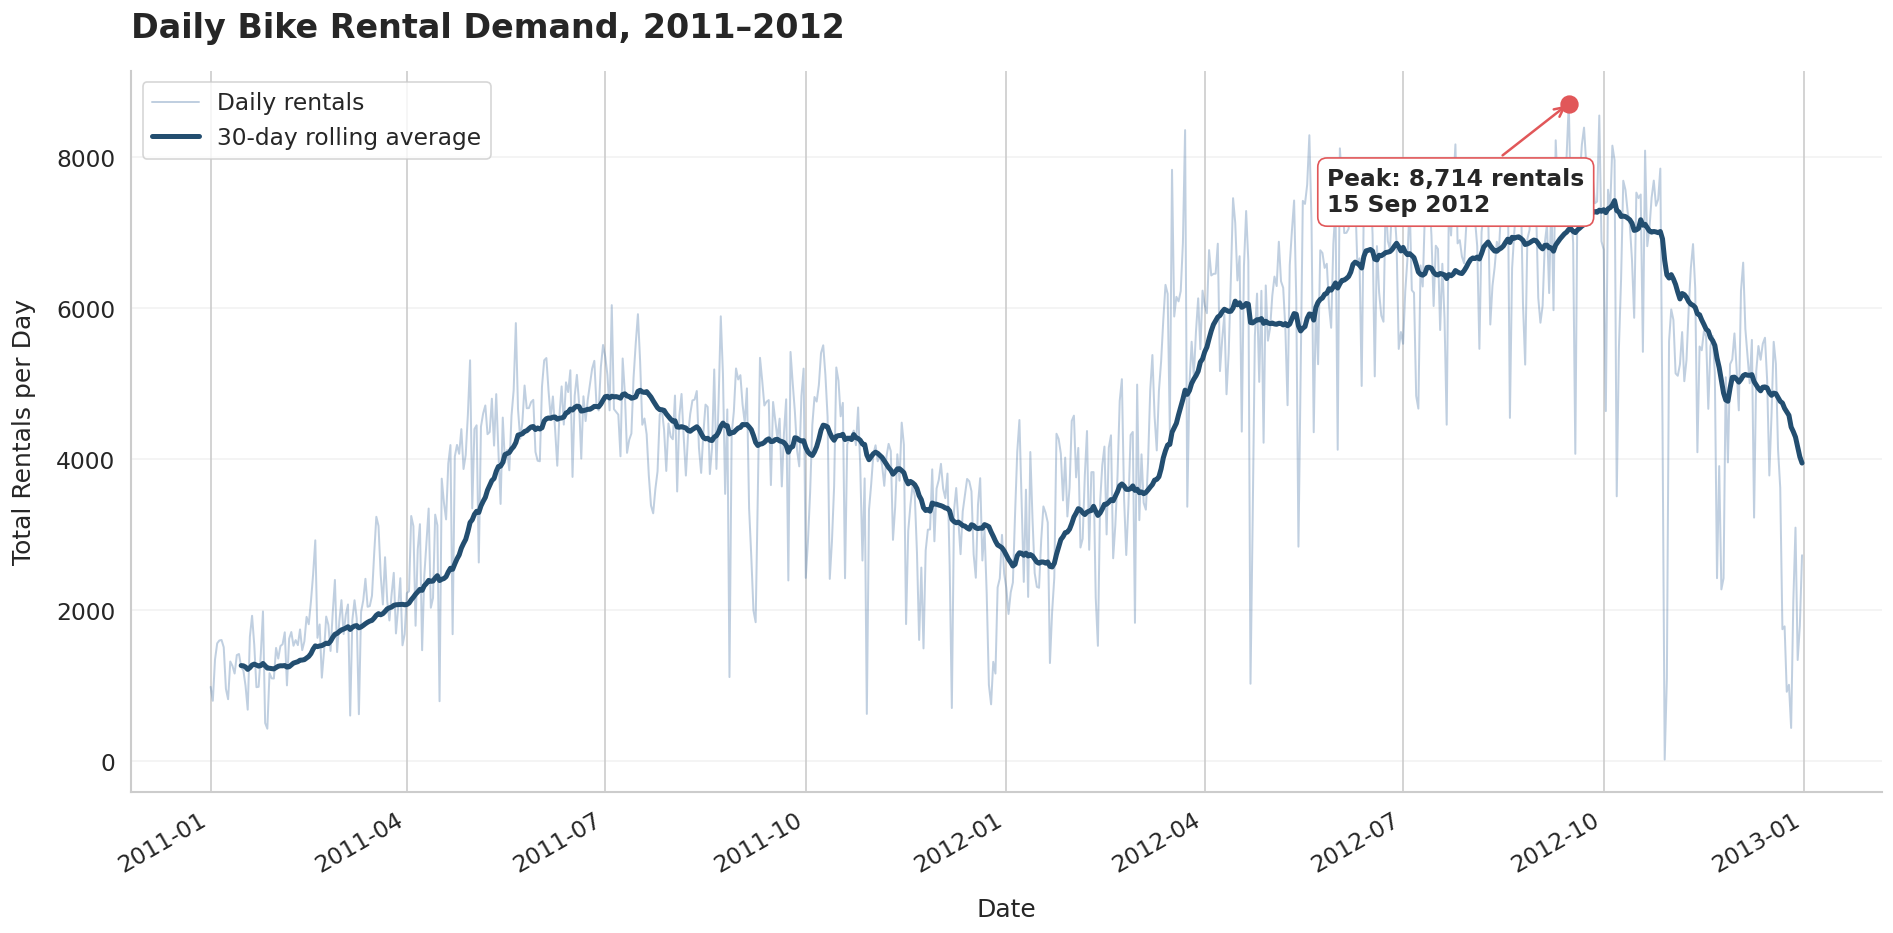

In [34]:
#Visualize how does daily bike rental demand change over time
def plot_daily_trends(data, save_path=None):

    plot_data = data.sort_values("dteday").copy()

    # Calculate the rolling average
    plot_data["rolling_30"] = plot_data["cnt"].rolling(
        window=30, min_periods=15
    ).mean()

    fig, ax = plt.subplots(figsize=(16, 8))

    # Plot daily rental counts
    ax.plot(
        plot_data["dteday"],
        plot_data["cnt"],
        color=COLORS["blue"],
        alpha=0.35,
        linewidth=1.2,
        label="Daily rentals"
    )

    # Plot the rolling average
    ax.plot(
        plot_data["dteday"],
        plot_data["rolling_30"],
        color=COLORS["navy"],
        linewidth=3,
        label="30-day rolling average"
    )

    # Highlight the day with the highest rental count
    peak_idx = plot_data["cnt"].idxmax()
    peak = plot_data.loc[peak_idx]

    ax.scatter(
        peak["dteday"],
        peak["cnt"],
        color=COLORS["red"],
        s=100,
        zorder=5
    )

    ax.annotate(
        f"Peak: {peak['cnt']:,} rentals\n"
        f"{peak['dteday']:%d %b %Y}",
        xy=(peak["dteday"], peak["cnt"]),
        xytext=(-145, -65),
        textcoords="offset points",
        fontsize=14,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="->",
            color=COLORS["red"],
            linewidth=1.5
        ),
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor=COLORS["red"]
        )
    )

    ax.set_title(
        "Daily Bike Rental Demand, 2011–2012",
        loc="left",
        pad=20
    )
    ax.set_xlabel("Date", labelpad=12)
    ax.set_ylabel("Total Rentals per Day", labelpad=12)

    ax.legend(loc="upper left")
    ax.grid(axis="y", alpha=0.25)

    fig.autofmt_xdate()
    plt.tight_layout()

    # Save the figure if a filename is provided
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

    return fig


# Generate Visualization 1
fig1 = plot_daily_trends(
    df_clean,
    save_path="figure1_daily_trends.png"
)


This line chart illustrates daily bike rental demand from 2011 to 2012, with the 30-day rolling average highlighting the overall trend. Rental demand generally increased throughout 2011, rising from approximately 1,200 rentals per day at the beginning of the year to around 4,800 during the summer. Demand subsequently declined towards the end of 2011 and reached a lower level in early 2012. From spring 2012, rentals increased substantially, remaining relatively high through summer and early autumn. The highest daily rental count was 8,714 on 15 September 2012. Following this peak, demand declined towards the end of 2012. These patterns suggest that bike rental demand varies over time, with noticeable seasonal fluctuations. The rolling average helps reveal these broader changes despite considerable day-to-day variation.

## Visualization 2: Seasonal Rental Demand

**Research question:** How does rental demand differ across seasons?

A boxplot was selected to compare daily rental distributions across spring, summer, fall, and winter. The median indicates typical demand, while the box and whiskers illustrate variability and potential outliers. This allows seasonal differences to be examined beyond average rental counts alone.

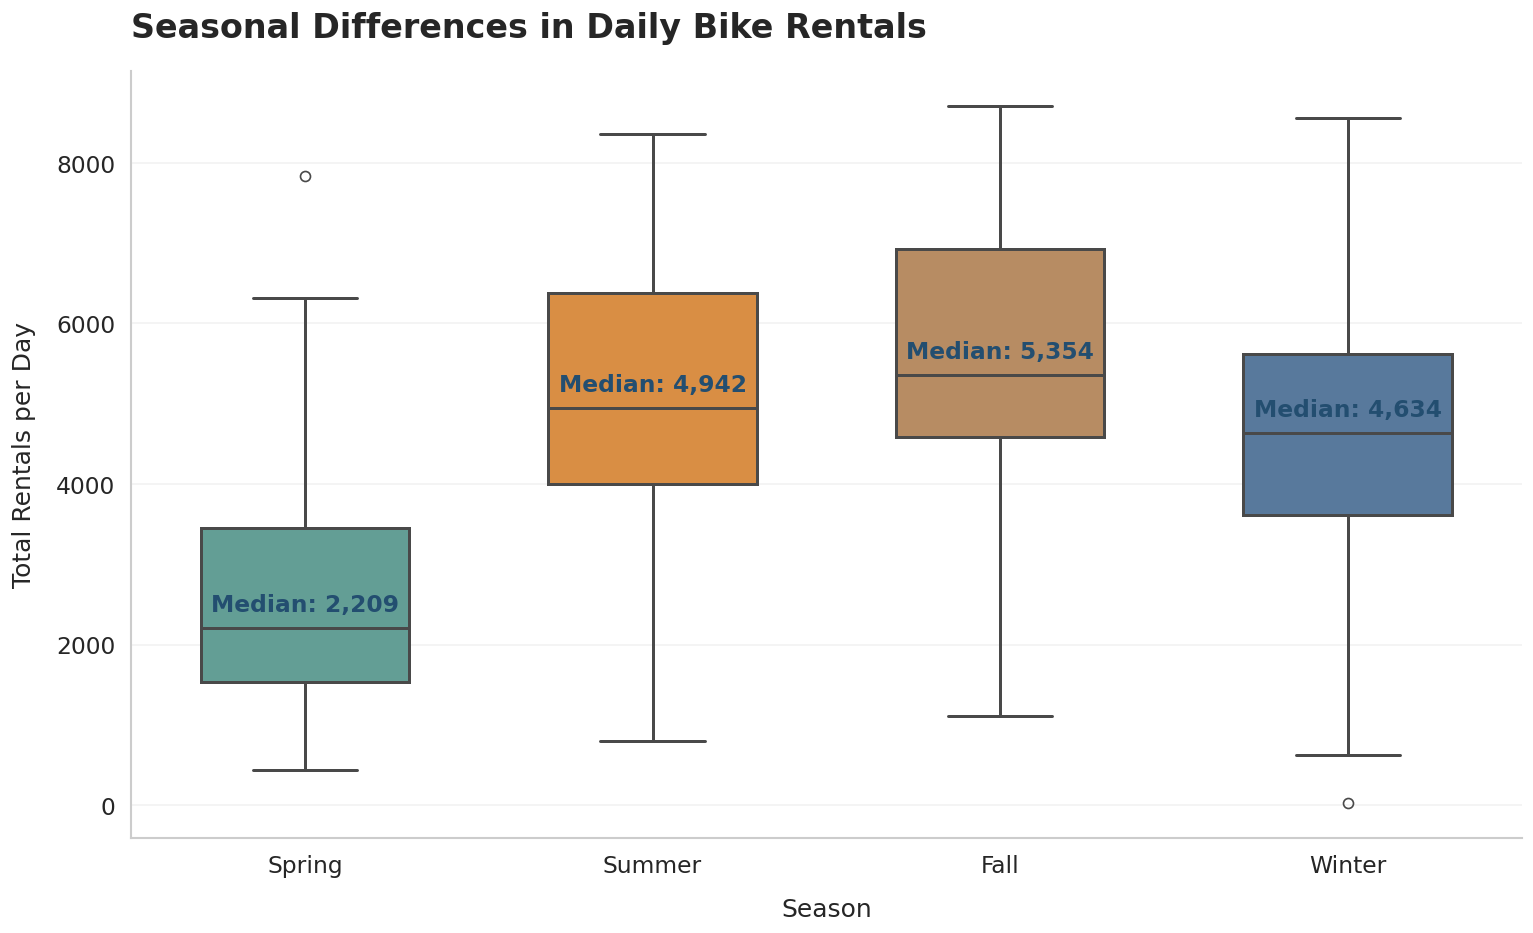

In [35]:
#Visualize how does rental demand differ across seasons
def plot_seasonal_demand(data, save_path=None):
    """
    Compare daily rental distributions across four seasons.

    Args:
        data (pandas.DataFrame): Cleaned dataset.
        save_path (str, optional): Filename for saving the plot.

    Returns:
        matplotlib.figure.Figure: Generated figure.
    """

    season_order = ["Spring", "Summer", "Fall", "Winter"]

    season_palette = {
        "Spring": COLORS["teal"],
        "Summer": COLORS["orange"],
        "Fall": "#C58B55",
        "Winter": COLORS["blue"]
    }

    fig, ax = plt.subplots(figsize=(13, 8))

    sns.boxplot(
        data=data,
        x="season_name",
        y="cnt",
        order=season_order,
        hue="season_name",
        hue_order=season_order,
        palette=season_palette,
        legend=False,
        width=0.6,
        linewidth=1.8,
        showfliers=True,
        ax=ax
    )

    # Annotate each seasonal median
    medians = data.groupby("season_name")["cnt"].median()

    for position, season in enumerate(season_order):
        if season in medians.index:
            median_value = medians[season]

            ax.annotate(
                f"Median: {median_value:,.0f}",
                xy=(position, median_value),
                xytext=(0, 10),
                textcoords="offset points",
                ha="center",
                fontsize=14,
                fontweight="bold",
                color=COLORS["navy"]
            )

    ax.set_title(
        "Seasonal Differences in Daily Bike Rentals",
        loc="left",
        pad=20
    )
    ax.set_xlabel("Season", labelpad=12)
    ax.set_ylabel("Total Rentals per Day", labelpad=12)

    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

    return fig


# Generate Visualization 2
fig2 = plot_seasonal_demand(
    df_clean,
    save_path="figure2_seasonal_boxplot.png"
)


According to this boxplot, daily rental distributions across the four seasons are compared. Fall recorded the highest median demand at 5,354 rentals per day, followed by summer at 4,942 and winter at 4,634. Spring had the lowest median, at 2,209 rentals per day. The relatively high median and broad distribution in fall indicate stronger rental demand during this season, while the lower median in spring suggests comparatively weaker usage. Summer and fall also show considerable variation in daily rentals, indicating that demand was not consistent throughout these seasons. A few outliers are visible, including an unusually high value in spring and a near-zero value in winter. These observations may represent unusual rental conditions and should be investigated rather than automatically removed. Overall, the chart indicates a clear association between season and bike rental demand.

## Visualization 3: Weather and Rental Demand

**Research question:** How is rental demand associated with weather conditions?

A bar chart was selected to compare mean daily rental counts across weather categories. Labels display the average rentals and sample size for each category. This visualisation helps identify differences in demand under varying weather conditions.

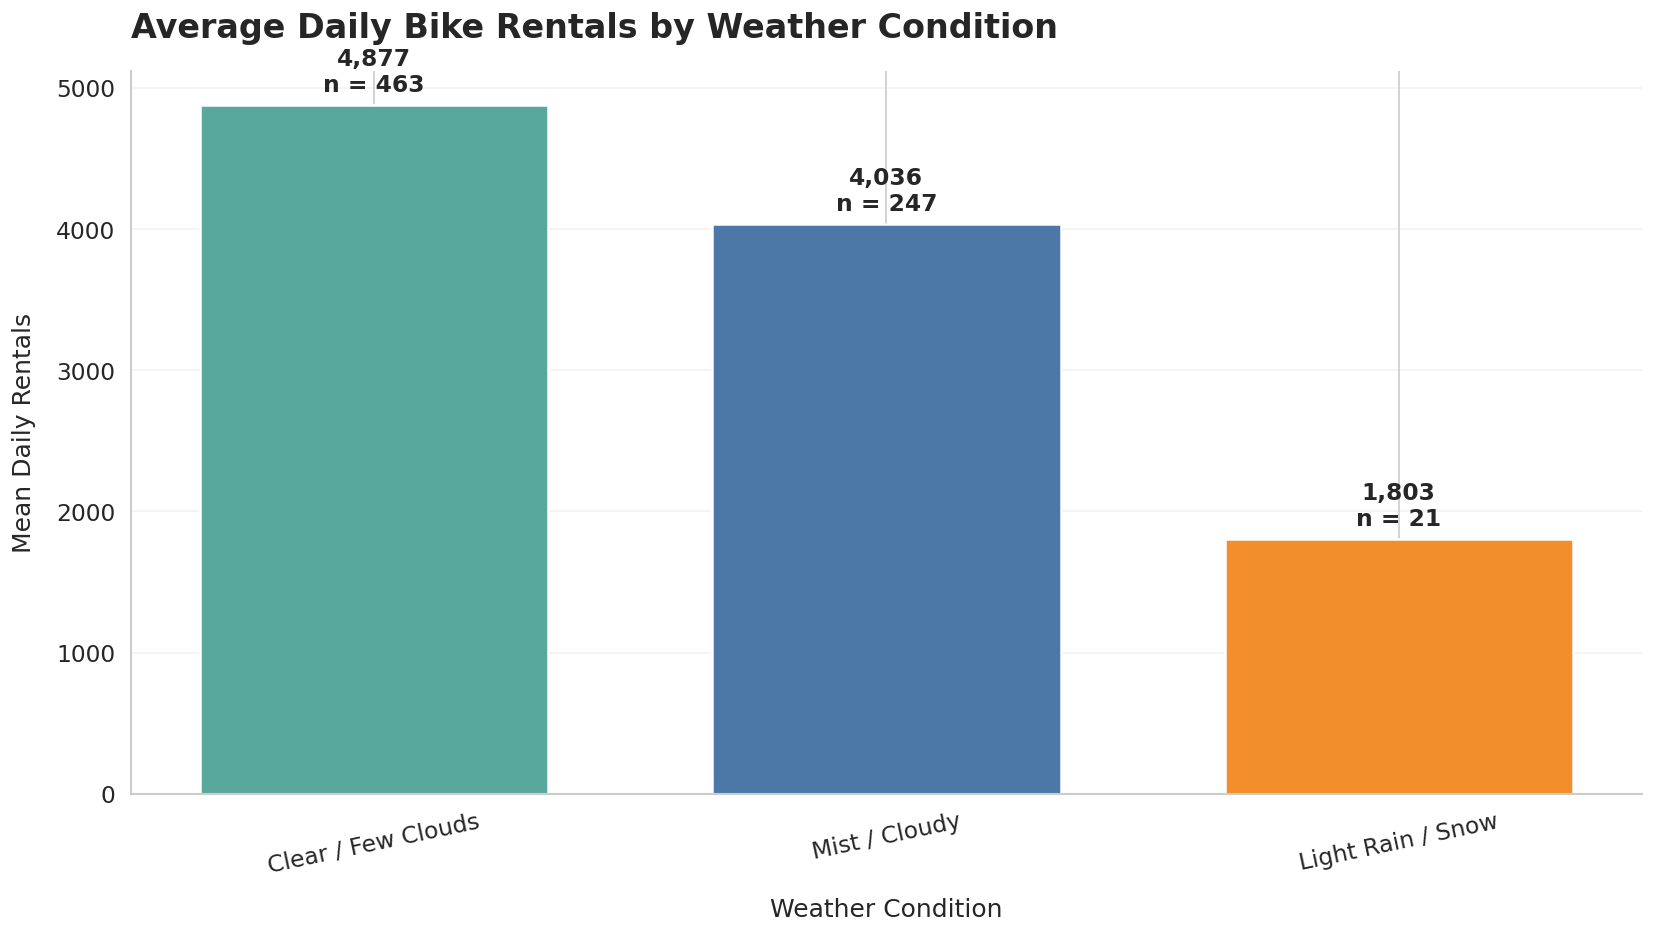

,mean,median,count
weather_name,,,
Clear / Few Clouds,4876.79,4844.0,463.0
Mist / Cloudy,4035.86,4040.0,247.0
Light Rain / Snow,1803.29,1817.0,21.0


In [36]:
#Visualize how is rental demand associated with weather conditions
def plot_weather_demand(data, save_path=None):

    weather_order = [
        "Clear / Few Clouds",
        "Mist / Cloudy",
        "Light Rain / Snow",
        "Heavy Rain / Snow"
    ]

    # Calculate average rental counts and sample sizes
    weather_summary = (
        data.groupby("weather_name", observed=True)["cnt"]
        .agg(["mean", "median", "count"])
        .reindex(weather_order)
        .dropna(subset=["mean"])
    )

    weather_colors = [
        COLORS["teal"],
        COLORS["blue"],
        COLORS["orange"],
        COLORS["red"]
    ]

    fig, ax = plt.subplots(figsize=(14, 8))

    bars = ax.bar(
        weather_summary.index,
        weather_summary["mean"],
        color=weather_colors[:len(weather_summary)],
        edgecolor="white",
        linewidth=1.5,
        width=0.68
    )

    # Annotate bars with mean rentals and sample size
    for bar, (_, row) in zip(
        bars, weather_summary.iterrows()
    ):
        height = bar.get_height()

        ax.annotate(
            f"{height:,.0f}\nn = {int(row['count'])}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=14,
            fontweight="bold"
        )

    ax.set_title(
        "Average Daily Bike Rentals by Weather Condition",
        loc="left",
        pad=20
    )
    ax.set_xlabel("Weather Condition", labelpad=12)
    ax.set_ylabel("Mean Daily Rentals", labelpad=12)

    ax.tick_params(axis="x", rotation=12, labelsize=14)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

    return fig, weather_summary


# Generate Visualization 3
fig3, weather_results = plot_weather_demand(
    df_clean,
    save_path="figure3_weather_comparison.png"
)

display(weather_results.round(2))


The bar chart compares mean daily rentals under different weather conditions. Clear or mostly clear conditions recorded the highest average, at 4,877 rentals per day across 463 observations. Misty or cloudy conditions had a lower average of 4,036 rentals across 247 observations. Light rain or snow recorded the lowest average, at just 1,803 rentals across 21 observations. This represents a substantial decrease in average demand under less favourable weather conditions. The results suggest that poorer weather is associated with reduced bike usage, potentially because rain or snow makes cycling less comfortable or convenient. However, the light rain or snow category contains considerably fewer observations than the other categories, so its average should be interpreted with some caution. Overall, the chart suggests that weather conditions are an important factor associated with daily bike rental demand.

# Final Analysis





In [37]:
#Analysis cleaned data for final result
def export_results(data, filenames=None):

    data.to_csv("cleaned_day.csv", index=False)

    if filenames is None:
        filenames = [
            "figure1_daily_trends.png",
            "figure2_seasonal_boxplot.png",
            "figure3_weather_comparison.png"
        ]

    print("Export completed.")
    print("Cleaned data: cleaned_day.csv")

    print("\nVisualization files:")
    for filename in filenames:
        print("-", filename)


# Call the export function
export_results(df_clean)


Export completed.
Cleaned data: cleaned_day.csv

Visualization files:
- figure1_daily_trends.png
- figure2_seasonal_boxplot.png
- figure3_weather_comparison.png


In [ ]:
# Download the cleaned CSV and visualization images for slides
#Optional, for creating powerpoint slides purpose only

from google.colab import files

for filename in [
    "cleaned_day.csv",
    "figure1_daily_trends.png",
    "figure2_seasonal_boxplot.png",
    "figure3_weather_comparison.png"
]:
    files.download(filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Problem 2: Visualisation Critique and Redesign


# 1. Critique the visualisation

# Chart A

In Chart A, the pie chart represents the percentage of bike rentals over the course of a day, by hour. The benefit of this visualisation is that it gives an overview of bike usage over the hours, and percentages can be used to determine when there are greater or less bike rentals. For instance, there is a maximum number of rentals at 17:00, which is 10.2% of the overall number of rentals, followed by 18:00 with 9.4% and 08:00 with 7.9%. The numbers indicate that the time when people tend to rent their bikes is mostly late afternoon and early evening. The pie chart is not the best way to represent data over 24 time periods, however, because it is hard to compare the size of many slices, particularly those with similar percentages. Early morning hour labels are crowded and overlapped, hard to read. Furthermore, numerous colours are used but have no consistent or definite meaning and can be a distraction for readers. The percentage labels are very informative, but the narrow slices and small text make them hard to read. In addition, the chart does not have a well-defined axis, making it difficult to compare the rental activity from year to year. A line chart would be a more effective alternative to the pie chart because it clearly illustrates changes in bike rental activity throughout the 24 hours of the day and will be demonstrated in next section.

# Chart B

For Chart B, the average number of bike rentals, by season, is displayed in the form of a bar chart. The advantage of this visualisation is that it is easy to compare how many rentals there are during each season in the bar chart and to see which season has the greatest and the least average number of rentals. The number of rentals per week is highest in Season 3, averaging around 236, and lowest in Season 1, averaging around 111. The chart also indicates that rentals go up markedly from Season 1 to Season 2, then up to Season 3, and down in Season 4. In addition, the chart is simple and uncluttered because it uses a single colour; the axis labels are clearly indicating the seasons and average number of rentals. The main drawback is that the seasons are not named with the words season 1, season 2, etc., and therefore the results are not very meaningful and it is difficult to interpret. Furthermore, the vertical axis is not zero starting, which further emphasizes the size of the differences between the bars and could lead readers to believe that the differences in rental activity are larger. It would also be good if the actual values above each bar were included in the chart so that it can be more accurately compared with the seasons. Overall, Chart B is effective for comparing the average number of bike rentals for four categories, but could be made clearer, more accurate, and more easily interpreted with descriptive labels for the seasons, starting the vertical axis at zero, and adding data labels.

# 2. Redesign the visualisation for chart A and B


In [38]:
#load the provided dataset
df = pd.read_csv("/content/dataset_x.csv")
display(df.head())


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,1/1/2011,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,1/1/2011,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,1/1/2011,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,1/1/2011,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,1/1/2011,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


# Justification for chart A

Replacing the pie chart with a line chart can also show the average number of bike rentals for each hour. A line chart is more suitable because the hour of the day is an ordered time variable. The horizontal axis follows the 24-hour clock, while the vertical axis shows average rentals per hour. Markers identify individual observations, and a light horizontal grid helps readers compare values.

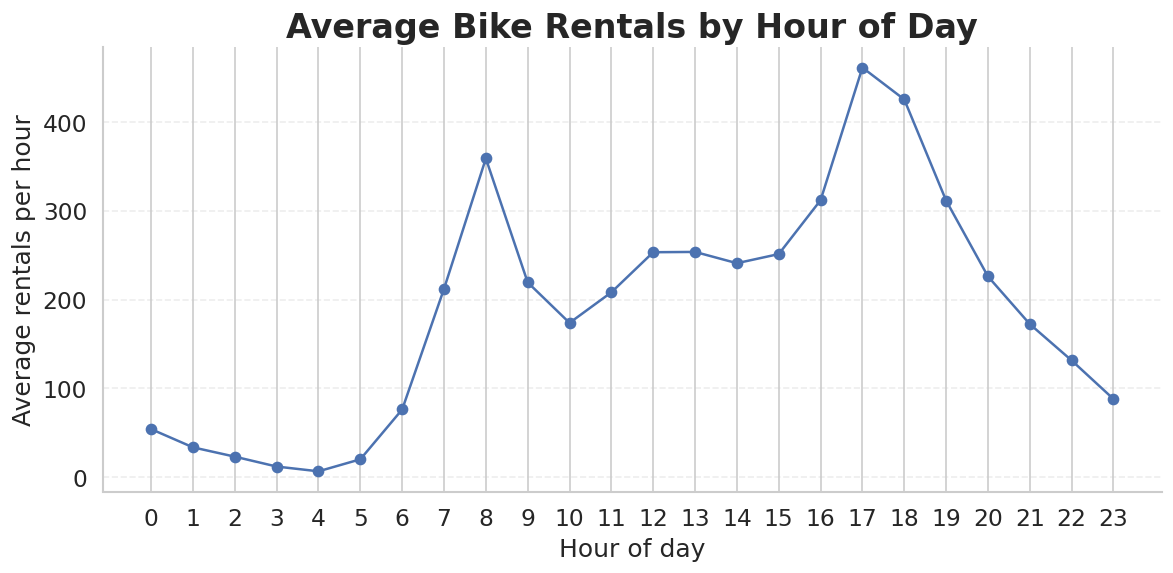

In [39]:
#create Line chart to improve Chart A
def plot_hourly_rentals(data):
    hourly = data.groupby("hr")["cnt"].mean()

    plt.figure(figsize=(10, 5))
    plt.plot(hourly.index, hourly.values, marker="o")

    plt.title("Average Bike Rentals by Hour of Day")
    plt.xlabel("Hour of day")
    plt.ylabel("Average rentals per hour")
    plt.xticks(range(24))
    plt.grid(axis="y", linestyle="--", alpha=0.35)

    plt.tight_layout()
    plt.savefig("chart_A_redesigned.png", dpi=200)
    plt.show()


#call the function
plot_hourly_rentals(df)


# Interpretation for improved chart A

The improved visualisation shows that bike rental demand varies considerably throughout the day. Average rentals are highest at 17:00, at approximately 461.5 rentals per hour, and lowest at 04:00, at approximately 6.4 rentals per hour. Demand rises sharply during the morning and reaches its strongest peak in the late afternoon. This pattern suggests that rental activity is concentrated around particular times rather than being evenly distributed throughout the day.



# Justification for chart B

Chart B, the bar chart is retained because it supports direct comparisons between discrete categories. However, it replaced by the numerical season codes with the names Spring, Summer, Autumn and Winter. Moreover, the vertical axis at zero, added numerical labels above the bars, and included a subtle horizontal grid are added to the existing one for better visualisation. These changes improve readability and make the differences easier to assess accurately.

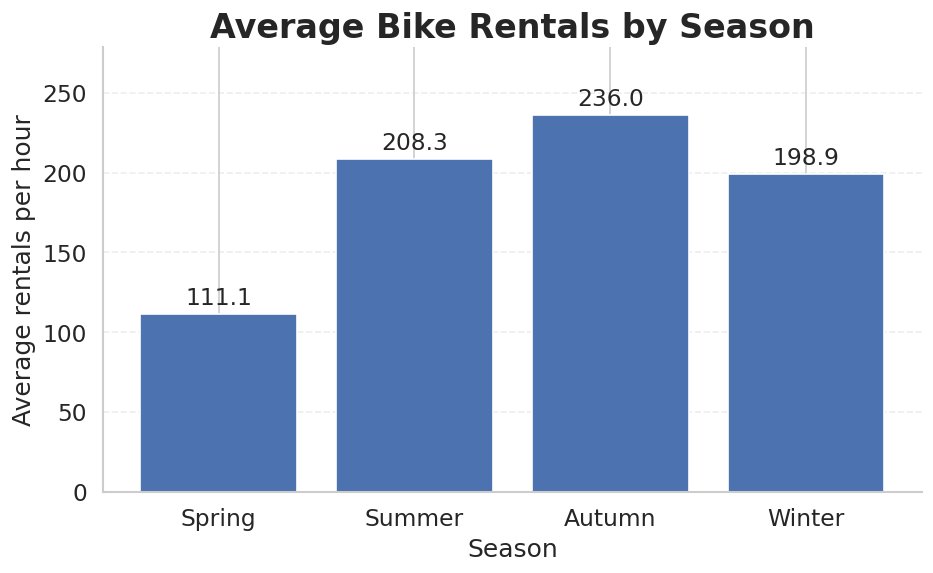

In [40]:
#create improved Bar Chart for Chart B
def plot_seasonal_rentals(data):
    seasons = {
        1: "Spring",
        2: "Summer",
        3: "Autumn",
        4: "Winter"
    }

    avg = data.groupby("season")["cnt"].mean()
    avg = avg.reindex([1, 2, 3, 4])

    labels = [seasons[s] for s in avg.index]

    plt.figure(figsize=(8, 5))
    bars = plt.bar(labels, avg.values)

    plt.title("Average Bike Rentals by Season")
    plt.xlabel("Season")
    plt.ylabel("Average rentals per hour")

    # Start the vertical axis at zero.
    plt.ylim(0, avg.max() * 1.18)

    # Display exact values above the bars.
    plt.bar_label(bars, fmt="%.1f", padding=3)

    plt.grid(axis="y", linestyle="--", alpha=0.35)
    plt.gca().set_axisbelow(True)

    plt.tight_layout()
    plt.savefig("chart_B_redesigned.png", dpi=200)
    plt.show()

#call the function
plot_seasonal_rentals(df)


# Interpretation for improved Chart B

According to the chart, autumn has the highest average rental count, at approximately 236.0 rentals per hour, followed by summer at 208.3, winter at 198.9 and spring at 111.1. The difference between autumn and spring indicates substantial seasonal variation in rental activity. However, these results demonstrate an association between season and rentals; they do not establish that season alone causes the differences.

# Additional Visualisation: Casual vs Registered Bike Rentals Across Seasons



# Research question:

**How does bike rental activity differ between casual and registered users across the four seasons?**

The purpose of this visualisation is to investigate whether casual and registered users demonstrate different seasonal rental patterns. Unlike the original charts, which focus on hourly rental distribution and overall seasonal averages, this visualisation introduces customer type as an additional dimension.

# Justification

A grouped bar chart was selected because it allows direct comparisons between casual and registered rentals within each season. The bars are placed side by side to make differences between user groups easy to identify. Season names replace numerical codes to improve readability, and the vertical axis starts at zero to support fair comparisons. A legend distinguishes the two user groups.

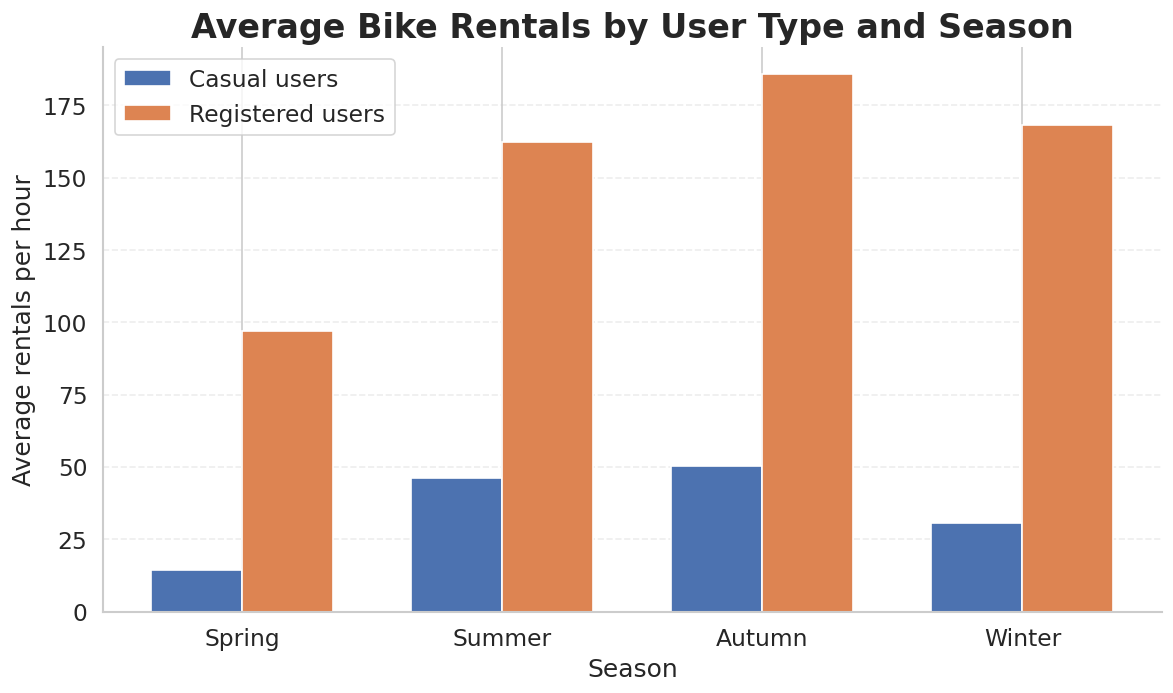

In [41]:
#Create grouped bar chart for additional visualisation
def plot_user_type_by_season(data):

    # Calculate average rentals for each user type
    seasonal = data.groupby("season")[
        ["casual", "registered"]
    ].mean()

    # Season labels
    seasons = ["Spring", "Summer", "Autumn", "Winter"]
    x = np.arange(len(seasons))
    width = 0.35

    # Create grouped bars
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.bar(
        x - width / 2,
        seasonal["casual"],
        width,
        label="Casual users"
    )

    ax.bar(
        x + width / 2,
        seasonal["registered"],
        width,
        label="Registered users"
    )

    # Add titles and labels
    ax.set_title("Average Bike Rentals by User Type and Season")
    ax.set_xlabel("Season")
    ax.set_ylabel("Average rentals per hour")
    ax.set_xticks(x)
    ax.set_xticklabels(seasons)

    # Start the y-axis at zero
    ax.set_ylim(bottom=0)

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.savefig("additional_chart_C.png", dpi=200)
    plt.show()


# Run the function
plot_user_type_by_season(df)

# Interpretation

The chart can be used to identify which user group records more rentals in each season and whether seasonal changes affect the groups differently. For example, if casual rentals increase more strongly during warmer seasons while registered rentals remain comparatively consistent, this may suggest different seasonal usage patterns. These observations must be confirmed using the actual chart. Differences in rental counts indicate associations and do not establish the reasons behind users' behaviour. Moreover, this complements the original charts by examining differences between customer groups rather than only comparing hours or seasons. It provides a more detailed understanding of rental demand and may help identify opportunities for seasonal marketing and customer engagement.